# 0.4.2 sandbox — compiled `minimize_optax` + `Functional.value_and_grad`

A scratch notebook to exercise the 0.4.2 optimizer work:

* **W0** — `Functional.value` / `grad` now accept `*args, **kwargs`, and there is a
  fused `Functional.value_and_grad(x) -> (value, grad)`.
* **W1** — `minimize_optax` is now a compiled, convergence-aware driver: the whole
  loop runs inside `jax.jit(jax.lax.while_loop(...))`, `value_and_grad` is evaluated
  once per iteration and cached, and it returns a rich `OptaxResult`.

Progress columns: **iteration · value `F(x)` · objective delta `ΔF = F_k - F_{k-1}` · grad norm**.


In [1]:
%matplotlib inline
import numpy as np
import jax
import optax
import optree
import matplotlib.pyplot as plt
import spacecore as sc

# optax is JAX-native and the loop is compiled, so use a JAX context.
# check_level='none' lets F.value / F.grad be traced without host-side checks.
jax.config.update("jax_enable_x64", True)

ctx = sc.Context(sc.JaxOps(), dtype=np.float64, check_level='none')
print('spacecore', getattr(sc, '__version__', '?'))


spacecore 0.4.1


## Test problems

Small quadratics with a known minimizer, built from the public API.

In [2]:
def euclidean_problem(ctx):
    """f(x) = 1/2 x^T diag(3,1) x - 3 x0 - 2 x1  ->  minimizer (1, 2)."""
    X = sc.DenseCoordinateSpace((2,), ctx)
    Q = sc.DenseLinOp(ctx.asarray([[3.0, 0.0], [0.0, 1.0]]), X, X, ctx)
    linear = sc.InnerProductFunctional(ctx.asarray([-3.0, -2.0]), X)
    F = sc.LinOpQuadraticForm(Q, linear)
    return X, F, np.array([1.0, 2.0])

def weighted_problem(ctx):
    """Non-trivial metric; minimizer -B^{-1}(w * c). Exercises the Riesz handoff."""
    B = np.array([[6.0, 1.0, 0.5], [1.0, 5.0, -0.25], [0.5, -0.25, 4.0]])
    w = np.array([2.0, 5.0, 11.0])
    c = np.array([0.3, -1.1, 0.7])
    X = sc.DenseCoordinateSpace((3,), ctx, geometry=sc.WeightedInnerProduct(ctx.asarray(w)))
    Q = sc.DenseLinOp(ctx.asarray(B / w[:, None]), X, X, ctx)
    F = sc.LinOpQuadraticForm(Q, sc.InnerProductFunctional(ctx.asarray(c), X))
    return X, F, -np.linalg.solve(B, w * c)

X, F, x_star = euclidean_problem(ctx)
X, F, x_star

(DenseCoordinateSpace(ℝ^2, backend='jax', dtype=float64),
 LinOpQuadraticForm(ℝ^2 → ℝ, backend='jax', dtype=float64),
 array([1., 2.]))

## W0 — fused `value_and_grad`

The base default returns `(value, grad)`; a subclass may override it with a single-pass AD.
Here it matches separate `value` / `grad` calls.

In [23]:
y = F.dom.zeros()

f = -2 * F + 2 * F


Array([0., 0.], dtype=float64)

In [3]:
x = ctx.asarray([0.5, -0.5])
value, grad = F.value_and_grad(x)
print('value:', float(value))
print('grad :', np.asarray(grad))
print('matches F.value?', np.allclose(float(value), float(F.value(x))))
print('matches F.grad? ', np.allclose(np.asarray(grad), np.asarray(F.grad(x))))

# W0 also widened value(x, *args, **kwargs); a plain functional simply ignores extras:
print('value(x, extra=1):', float(F.value(x)))


value: 0.0
grad : [-1.5 -2.5]
matches F.value? True
matches F.grad?  True
value(x, extra=1): 0.0


## W1 — compiled `minimize_optax`, verbose run

`verbose=2` prints the four-column progress table on the `log_every` cadence, then a summary.

In [4]:
res = sc.minimize_optax(
    F, X.zeros(), optax.adam(1e-1),
    max_iter=1000, tol=1e-9, verbose=2, log_every=100,
)
print('\nminimizer :', np.asarray(res.x_element), ' target:', x_star)
print('success   :', res.success, '| status:', res.status, '| iters:', res.num_iters)
print('final value:', res.final_value, '| final grad_norm:', res.final_grad_norm)


   iter               value               delta           grad_norm
-------------------------------------------------------------------
      0     +0.00000000e+00     +0.00000000e+00           3.606e+00
    100     -3.49995159e+00     -6.09763197e-06           1.219e-02
    200     -3.50000000e+00     -1.50581769e-10           6.088e-05
    300     -3.50000000e+00     -2.30926389e-14           2.634e-07
    400     -3.50000000e+00     -4.44089210e-16           1.849e-09
    402     -3.50000000e+00     -8.88178420e-16           3.647e-10
-------------------------------------------------------------------
status   : converged
iters    : 402  (nfev=403, njev=403, ls=0)
value    : -3.50000000e+00
grad_norm: 3.647e-10
compile: 0.08 s   execution: 0.00 s   avg/iter: 0.007 ms

minimizer : [1. 2.]  target: [1. 2.]
success   : True | status: 0 | iters: 402
final value: -3.5000000000000004 | final grad_norm: 3.6467119214945345e-10


In [19]:
Fnp = F.convert('numpy')

sc.minimize_scipy(F, F.dom.zeros(), method='Newton-CG')

   message: Optimization terminated successfully.
   success: True
    status: 0
       fun: -3.5
         x: [ 1.000e+00  2.000e+00]
       nit: 3
       jac: [ 2.733e-08  1.192e-08]
      nfev: 4
      njev: 10
      nhev: 0
 x_element: [ 1.000e+00  2.000e+00]

In [6]:
res

OptaxResult(success=True, status=0, message='converged', num_iters=402, nfev=403, njev=403, n_linesearch_steps=0, final_value=-3.5000000000000004, final_grad_norm=3.6467119214945345e-10, x_element=array([1., 2.]), history={'iteration': array([  0, 100, 200, 300, 400, 402]), 'value': array([ 0.        , -3.49995159, -3.5       , -3.5       , -3.5       ,
       -3.5       ]), 'value_delta': array([ 0.00000000e+00, -6.09763197e-06, -1.50581769e-10, -2.30926389e-14,
       -4.44089210e-16, -8.88178420e-16]), 'grad_norm': array([3.60555128e+00, 1.21885258e-02, 6.08835510e-05, 2.63355560e-07,
       1.84883314e-09, 3.64671192e-10])}, compile_seconds=0.08347462501842529, execution_seconds=0.0026320829638279974, average_iteration_ms=0.006547470059273626)

## History + convergence plot

`res.history` has `iteration`, `value`, `value_delta` (= `ΔF`), and `grad_norm`.

history columns: ['iteration', 'value', 'value_delta', 'grad_norm']


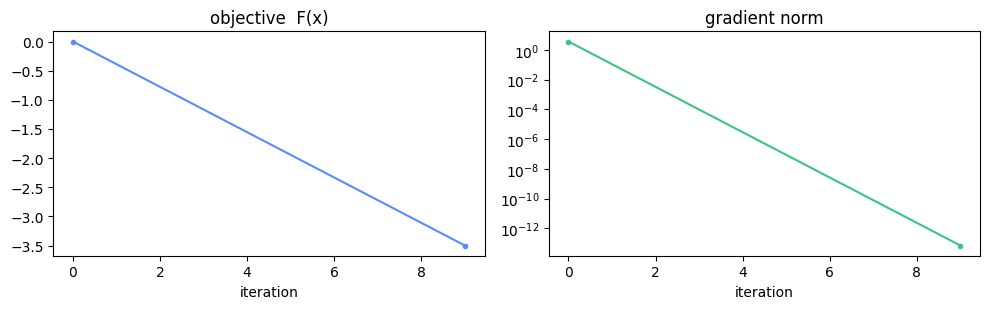

In [7]:
res = sc.minimize_optax(
    F, X.zeros(), optax.lbfgs(),
    max_iter=2000, tol=1e-12, history_every=10, verbose=0,
)
h = res.history
print('history columns:', list(h))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h['iteration'], h['value'], marker='.')
ax[0].set(title='objective  F(x)', xlabel='iteration')
ax[1].semilogy(h['iteration'], h['grad_norm'], marker='.', color='C3')
ax[1].set(title='gradient norm', xlabel='iteration')
fig.tight_layout()
plt.show()


## `progress_callback` — replayed from history after the loop

A compiled loop can't call Python live, so each recorded row is replayed once the run finishes.

In [8]:
rows = []
res = sc.minimize_optax(
    F, X.zeros(), optax.sgd(1e-2),
    max_iter=5000, tol=1e-5, history_every=100, verbose=0,
    progress_callback=rows.append,
)
for r in rows:
    print(r)


{'iteration': 0, 'value': 0.0, 'value_delta': 0.0, 'grad_norm': 3.605551275463989}
{'iteration': 100, 'value': -3.2286487887690827, 'value_delta': -0.005653710484801788, 'grad_norm': 0.7458350142771583}
{'iteration': 200, 'value': -3.4640912236335515, 'value_delta': -0.0007294196422908961, 'grad_norm': 0.26804520513959623}
{'iteration': 300, 'value': -3.495189964074074, 'value_delta': -9.766395009291884e-05, 'grad_norm': 0.09808231861586475}
{'iteration': 400, 'value': -3.499355555235023, 'value_delta': -1.3084840789101548e-05, 'grad_norm': 0.03590110982720799}
{'iteration': 500, 'value': -3.4999136575050898, 'value_delta': -1.753102389479011e-06, 'grad_norm': 0.01314096610507359}
{'iteration': 600, 'value': -3.499988431860617, 'value_delta': -2.3488008782379666e-07, 'grad_norm': 0.004810018582746713}
{'iteration': 700, 'value': -3.4999984501044468, 'value_delta': -3.146915750207313e-08, 'grad_norm': 0.0017606223633649342}
{'iteration': 800, 'value': -3.4999997923454975, 'value_delta':

## `project` hook — constrained descent

An optional retraction applied after each optax update. Here it pins coordinate 0 to zero.

In [9]:
project = lambda p: p.at[0].set(0.0)
res = sc.minimize_optax(
    F, X.zeros(), optax.adam(1e-1),
    max_iter=300, tol=1e-8, project=project, verbose=0,
)
print('x_element:', np.asarray(res.x_element), ' (coordinate 0 pinned to 0)')


x_element: [0.         2.00000017]  (coordinate 0 pinned to 0)


## Weighted metric — Riesz handoff

On a weighted space the coordinate gradient is `X.riesz(F.grad)`; optax still lands on the
metric minimizer.

In [10]:
Xw, Fw, xw_star = weighted_problem(ctx)
res = sc.minimize_optax(Fw, Xw.zeros(), optax.adam(5e-2), max_iter=8000, tol=1e-5, verbose=0)
print('minimizer:', np.asarray(res.x_element))
print('target   :', xw_star)
print('success  :', res.success, '| iters:', res.num_iters)


minimizer: [-0.11807237  1.03132681 -1.84578367]
target   : [-0.11807229  1.0313253  -1.84578313]
success  : True | iters: 248


## Tree space — pytree parameters

`x0` may be a pytree of arrays; the minimizer comes back in the same structure.

In [11]:
treedef = optree.tree_structure((0, 0))
Xa = sc.DenseCoordinateSpace((2,), ctx)
Xb = sc.DenseCoordinateSpace((1,), ctx)
Xt = sc.TreeSpace(treedef, (Xa, Xb), ctx=ctx)
Ft = sc.LinOpQuadraticForm(sc.IdentityLinOp(Xt, ctx))
x0 = (ctx.asarray([3.0, -1.0]), ctx.asarray([2.0]))
res = sc.minimize_optax(Ft, x0, optax.sgd(0.2), max_iter=500, tol=1e-4, verbose=0)
print('x_element   :', res.x_element)
print('flattened ~0:', np.asarray(Xt.flatten(res.x_element)))


x_element   : TreeElement(TreeSpace(Tree(ℝ^2, ℝ^1)), leaves=(<array shape=(2,), dtype=float64>, <array shape=(1,), dtype=float64>))
flattened ~0: [ 6.69022356e-05 -2.23007452e-05  4.46014904e-05]


## Divergence → finiteness stop (`status == 2`)

A wildly oversized step overflows; the loop stops on the finiteness guard, not the cap.

In [12]:
res = sc.minimize_optax(Fw, Xw.zeros(), optax.sgd(1e20), max_iter=1000, tol=1e-6, verbose=0)
print('status :', res.status, '| success:', res.success)
print('message:', res.message)


status : 2 | success: False
message: diverged: value or gradient became nonfinite


## Your sandbox

Swap in your own `Functional` / optimizer / schedule below. Anything with a JAX-backed
inner-product domain and an implemented `grad` works.

In [13]:
# ctx = sc.Context(sc.JaxOps(), dtype=np.float32, check_level='none')
# X, F, x_star = euclidean_problem(ctx)
# opt = optax.adam(optax.cosine_decay_schedule(1e-1, 1000))
# res = sc.minimize_optax(F, X.zeros(), opt, max_iter=1000, tol=1e-6, verbose=2)
# res
